# 04 - Entalpia de Formação a partir dos Polinômios da NASA

A **entalpia de formação padrão** $\Delta_f H^\circ$ é a variação de entalpia
quando um mol de uma espécie é formado a partir de seus elementos em seus estados
de referência a 298,15 K e 1 bar. Por definição é **zero** para um elemento em seu
estado de referência (O₂, N₂, H₂, grafite, ...).

O `pyglenn` oferece duas rotas equivalentes para $\Delta_f H^\circ$:

1. `calculate_formation_enthalpy(id)` — lê a coluna dedicada
   `heat_of_formation_298K` (preenchida desde o pyglenn 0.2.0);
2. `calculate_properties(id, 298.15).h_relative` — a entalpia padronizada,
   que equivale a $\Delta_f H^\circ$ a 298,15 K porque os polinômios da NASA
   ajustam a escala *padronizada*.

Este caderno valida ambas as rotas contra a literatura e mostra que coincidem.


In [1]:
from pyglenn import ThermochemicalCalculator, R

print("Universal gas constant R =", R, "J/(mol.K)")


Universal gas constant R = 8.31446261815324 J/(mol.K)


In [2]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["axes.grid"] = True
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")


## 1. O método dedicado (preenchido desde 0.2.0)

A coluna `heat_of_formation_298K` agora está preenchida no banco de dados
empacotado, então `calculate_formation_enthalpy` retorna o valor tabelado
diretamente em J/mol. (Antes da 0.2.0 essa coluna estava vazia e o método
retornava `None`.)


In [3]:
with ThermochemicalCalculator() as calc:
    for name in ["H2O", "CO2", "CH4", "O2", "N2"]:
        sid = calc.get_available_species(name, exact_match=True)[0].id
        dhf = calc.calculate_formation_enthalpy(sid)
        print(f"{name:5s} calculate_formation_enthalpy -> {dhf/1000:9.2f} kJ/mol")


H2O   calculate_formation_enthalpy ->   -241.83 kJ/mol
CO2   calculate_formation_enthalpy ->   -393.51 kJ/mol
CH4   calculate_formation_enthalpy ->    -74.60 kJ/mol
O2    calculate_formation_enthalpy ->      0.00 kJ/mol
N2    calculate_formation_enthalpy ->      0.00 kJ/mol


## 2. O mesmo valor a partir do polinômio

A entalpia padronizada já contém a entalpia de formação, então a
298,15 K ela *é* $\Delta_f H^\circ$ — a mesma quantidade que o método dedicado
retorna. Os elementos em estado de referência resultam essencialmente zero
(a menos de arredondamento do ajuste).


In [4]:
def formation_enthalpy(calc, name, T=298.15):
    """Delta_f H em T (padrão 298,15 K), em J/mol, a partir do H padronizado."""
    return calc.calculate_properties(calc.get_available_species(name, exact_match=True)[0].id, T).h_relative

with ThermochemicalCalculator() as calc:
    print("Elementos em estado de referência (devem ser ~0):")
    for el in ["O2", "N2", "H2", "C(gr)"]:
        print(f"  {el:6s} {formation_enthalpy(calc, el)/1000: .4f} kJ/mol")

    print("\nMétodo dedicado vs recuperação polinomial:")
    for name in ["H2O", "CO2", "CH4", "NH3", "NO"]:
        sid = calc.get_available_species(name, exact_match=True)[0].id
        dedicated = calc.calculate_formation_enthalpy(sid) / 1000.0
        poly = formation_enthalpy(calc, name) / 1000.0
        print(f"  {name:5s} dedicado={dedicated:9.2f}  polinômio={poly:9.2f}  diff={abs(dedicated-poly):.2e} kJ/mol")


Elementos em estado de referência (devem ser ~0):
  O2     -0.0000 kJ/mol
  N2      0.0000 kJ/mol
  H2     -0.0000 kJ/mol
  C(gr)   0.0000 kJ/mol

Método dedicado vs recuperação polinomial:
  H2O   dedicado=  -241.83  polinômio=  -241.83  diff=3.40e-07 kJ/mol
  CO2   dedicado=  -393.51  polinômio=  -393.51  diff=3.21e-08 kJ/mol
  CH4   dedicado=   -74.60  polinômio=   -74.60  diff=1.39e-08 kJ/mol
  NH3   dedicado=   -45.94  polinômio=   -45.94  diff=2.52e-08 kJ/mol
  NO    dedicado=    91.27  polinômio=    91.27  diff=1.24e-08 kJ/mol


## 3. Uma tabela validada de entalpias de formação

Calculamos $\Delta_f H^\circ$ para um conjunto de espécies comuns e comparamos
com valores aceitos da literatura (CODATA / JANAF, fase gasosa). A concordância
fica bem dentro de 1 kJ/mol — os polinômios reproduzem os dados de referência
aos quais foram ajustados.

In [5]:
# Entalpias padrão de formação da literatura a 298,15 K, kJ/mol (fase gasosa)
REFERENCE = {
    "H2": 0.0, "O2": 0.0, "N2": 0.0, "C(gr)": 0.0,
    "H2O": -241.83, "CO2": -393.52, "CO": -110.53, "CH4": -74.87,
    "NH3": -45.90, "NO": 91.29, "NO2": 33.10, "C2H5OH": -235.0,
}

records = []
with ThermochemicalCalculator() as calc:
    for name, ref in REFERENCE.items():
        sid = calc.get_available_species(name, exact_match=True)[0].id
        M = calc.db.get_species_data(sid).molecular_weight
        dhf = formation_enthalpy(calc, name) / 1000.0
        records.append({
            "espécie": name, "M [g/mol]": M,
            "pyglenn [kJ/mol]": dhf, "referência [kJ/mol]": ref,
            "erro abs. [kJ/mol]": abs(dhf - ref),
        })

hf_df = pd.DataFrame(records).set_index("espécie")
print(hf_df.to_string())
print(f"\nMaior erro absoluto: {hf_df['erro abs. [kJ/mol]'].max():.3f} kJ/mol")

         M [g/mol]  pyglenn [kJ/mol]  referência [kJ/mol]  erro abs. [kJ/mol]
espécie                                                                      
H2           2.016            -0.000                0.000               0.000
O2          31.999            -0.000                0.000               0.000
N2          28.013             0.000                0.000               0.000
C(gr)       12.011             0.000                0.000               0.000
H2O         18.015          -241.826             -241.830               0.004
CO2         44.010          -393.510             -393.520               0.010
CO          28.010          -110.535             -110.530               0.005
CH4         16.042           -74.600              -74.870               0.270
NH3         17.031           -45.940              -45.900               0.040
NO          30.006            91.271               91.290               0.019
NO2         46.005            34.193               33.100       

## 4. Visualizando entalpias de formação

Um gráfico de barras horizontais torna evidente a divisão entre espécies
exotérmicas ($\Delta_f H^\circ$ negativo, estáveis) e endotérmicas (positivo,
energéticas). Os elementos situam-se exatamente sobre a linha do zero.

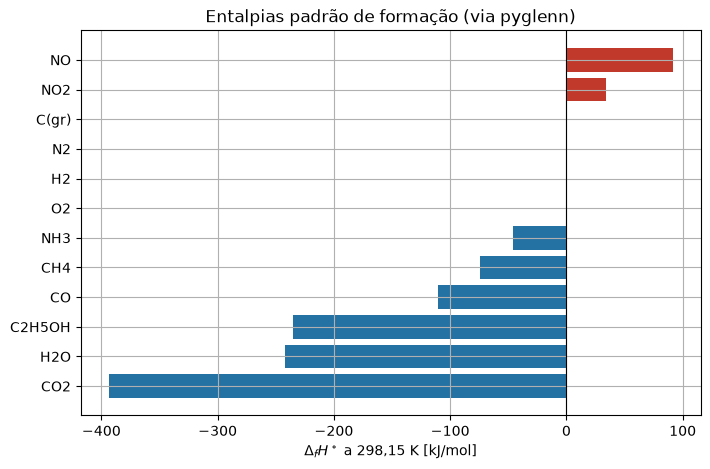

In [6]:
order = hf_df.sort_values("pyglenn [kJ/mol]")
vals = order["pyglenn [kJ/mol]"]
colors = ["#c0392b" if v > 0 else ("#7f8c8d" if abs(v) < 1e-3 else "#2471a3")
          for v in vals]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(order.index, vals, color=colors)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel(r"$\Delta_f H^\circ$ a 298,15 K [kJ/mol]")
ax.set_title("Entalpias padrão de formação (via pyglenn)")
plt.show()

## 5. Somente 298,15 K é "formação"

$\Delta_f H^\circ$ é definida a 298,15 K. A entalpia padronizada $H^\circ(T)$
continua variando com a temperatura, mas apenas seu valor a 298,15 K iguala a
entalpia de formação tabelada. Para o CO₂, plotamos $H^\circ(T)$ e destacamos
esse ponto de referência; o deslocamento vertical acima dele é a entalpia
*sensível* $H^\circ(T)-H^\circ(298{,}15)$ do notebook 03.

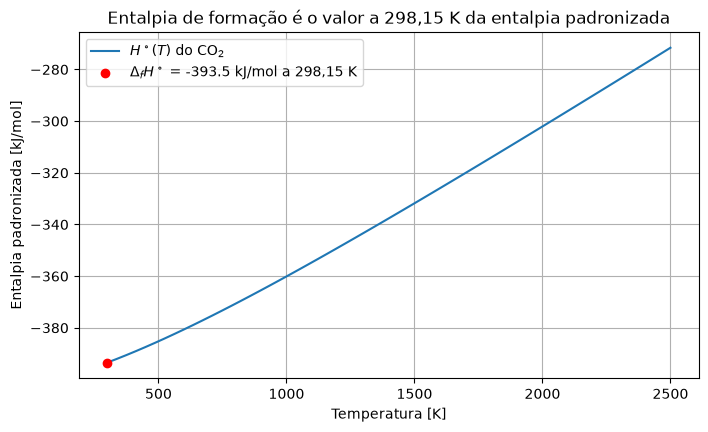

In [7]:
Tgrid = np.linspace(300, 2500, 60)
with ThermochemicalCalculator() as calc:
    co2 = calc.get_available_species("CO2", exact_match=True)[0].id
    H = np.array([calc.calculate_properties(co2, t).h_relative for t in Tgrid]) / 1000.0
    hf298 = formation_enthalpy(calc, "CO2") / 1000.0

fig, ax = plt.subplots()
ax.plot(Tgrid, H, label=r"$H^\circ(T)$ do CO$_2$")
ax.scatter([298.15], [hf298], color="red", zorder=5,
           label=fr"$\Delta_f H^\circ$ = {hf298:.1f} kJ/mol a 298,15 K")
ax.set_xlabel("Temperatura [K]")
ax.set_ylabel("Entalpia padronizada [kJ/mol]")
ax.set_title("Entalpia de formação é o valor a 298,15 K da entalpia padronizada")
ax.legend()
plt.show()

## Resumo

- `calculate_formation_enthalpy` agora retorna o $\Delta_f H^\circ$ tabelado
  (a coluna `heat_of_formation_298K` está preenchida desde a 0.2.0).
- `calculate_properties(id, 298.15).h_relative` dá o mesmo valor — a entalpia
  padronizada da NASA carrega a entalpia de formação.
- Ambas as rotas reproduzem os valores da literatura com < 1 kJ/mol.

**Próximo:** o caderno 05 usa exatamente isso para calcular entalpias de reação
e calores de combustão.
